#  Задание 3.5 — Классификация погоды по фотографиям

## Импорты:

In [7]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.utils import make_grid

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)
from PIL import Image
from tqdm import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print(" Используется Apple MPS (Metal GPU)")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print(" Используется CUDA GPU")
else:
    DEVICE = torch.device("cpu")
    print("  Используется CPU")

IMG_SIZE   = 128       # Размер изображения
BATCH_SIZE = 32
EPOCHS_MLP = 30
EPOCHS_CNN = 30
EPOCHS_TL  = 15        # Transfer Learning сходится быстрее
LR         = 1e-3

DATA_DIR = Path("/Users/arseniy/Documents/Машинное обучение/Multi-class Weather Dataset")

print(f" {DATA_DIR}")

 Используется Apple MPS (Metal GPU)
 /Users/arseniy/Documents/Машинное обучение/Multi-class Weather Dataset


## 2. Загрузка и анализ датасета

Классы: ['Cloudy', 'Rain', 'Shine', 'Sunrise']

Распределение по классам:
  Cloudy    :  300 изображений (26.7%)
  Rain      :  215 изображений (19.1%)
  Shine     :  253 изображений (22.5%)
  Sunrise   :  357 изображений (31.7%)
  ИТОГО     : 1125


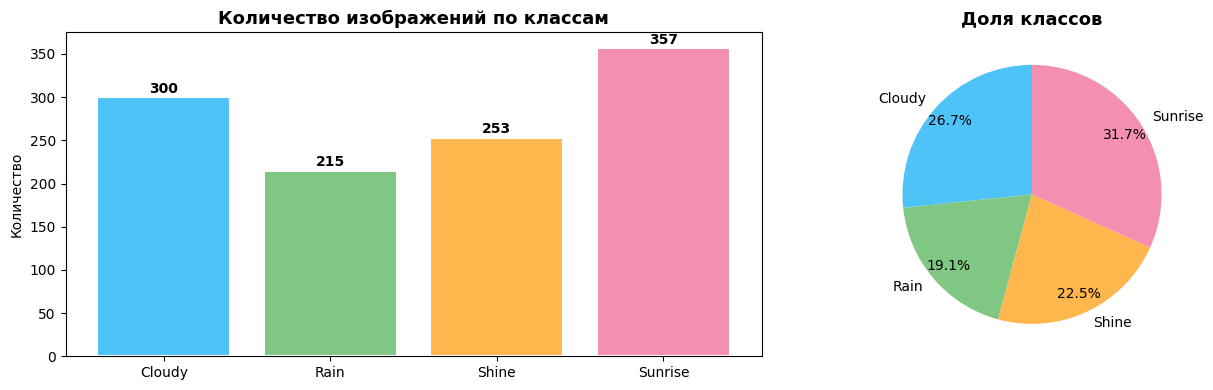

In [8]:
# ── Проверка структуры датасета ────────────────────────────────────────────
assert DATA_DIR.exists(), f"Папка {DATA_DIR} не найдена! Проверьте путь."

classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
print(f"Классы: {classes}")

counts = {cls: len(list((DATA_DIR / cls).glob("*.*"))) for cls in classes}
total  = sum(counts.values())
print(f"\nРаспределение по классам:")
for cls, n in counts.items():
    print(f"  {cls:10s}: {n:4d} изображений ({n/total*100:.1f}%)")
print(f"  {'ИТОГО':10s}: {total:4d}")

# ── График распределения ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

colors = ['#4FC3F7', '#81C784', '#FFB74D', '#F48FB1']
axes[0].bar(counts.keys(), counts.values(), color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Количество изображений по классам', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Количество')
for i, (cls, n) in enumerate(counts.items()):
    axes[0].text(i, n + 5, str(n), ha='center', fontweight='bold')

axes[1].pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%',
            colors=colors, startangle=90, pctdistance=0.85)
axes[1].set_title('Доля классов', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('01_class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

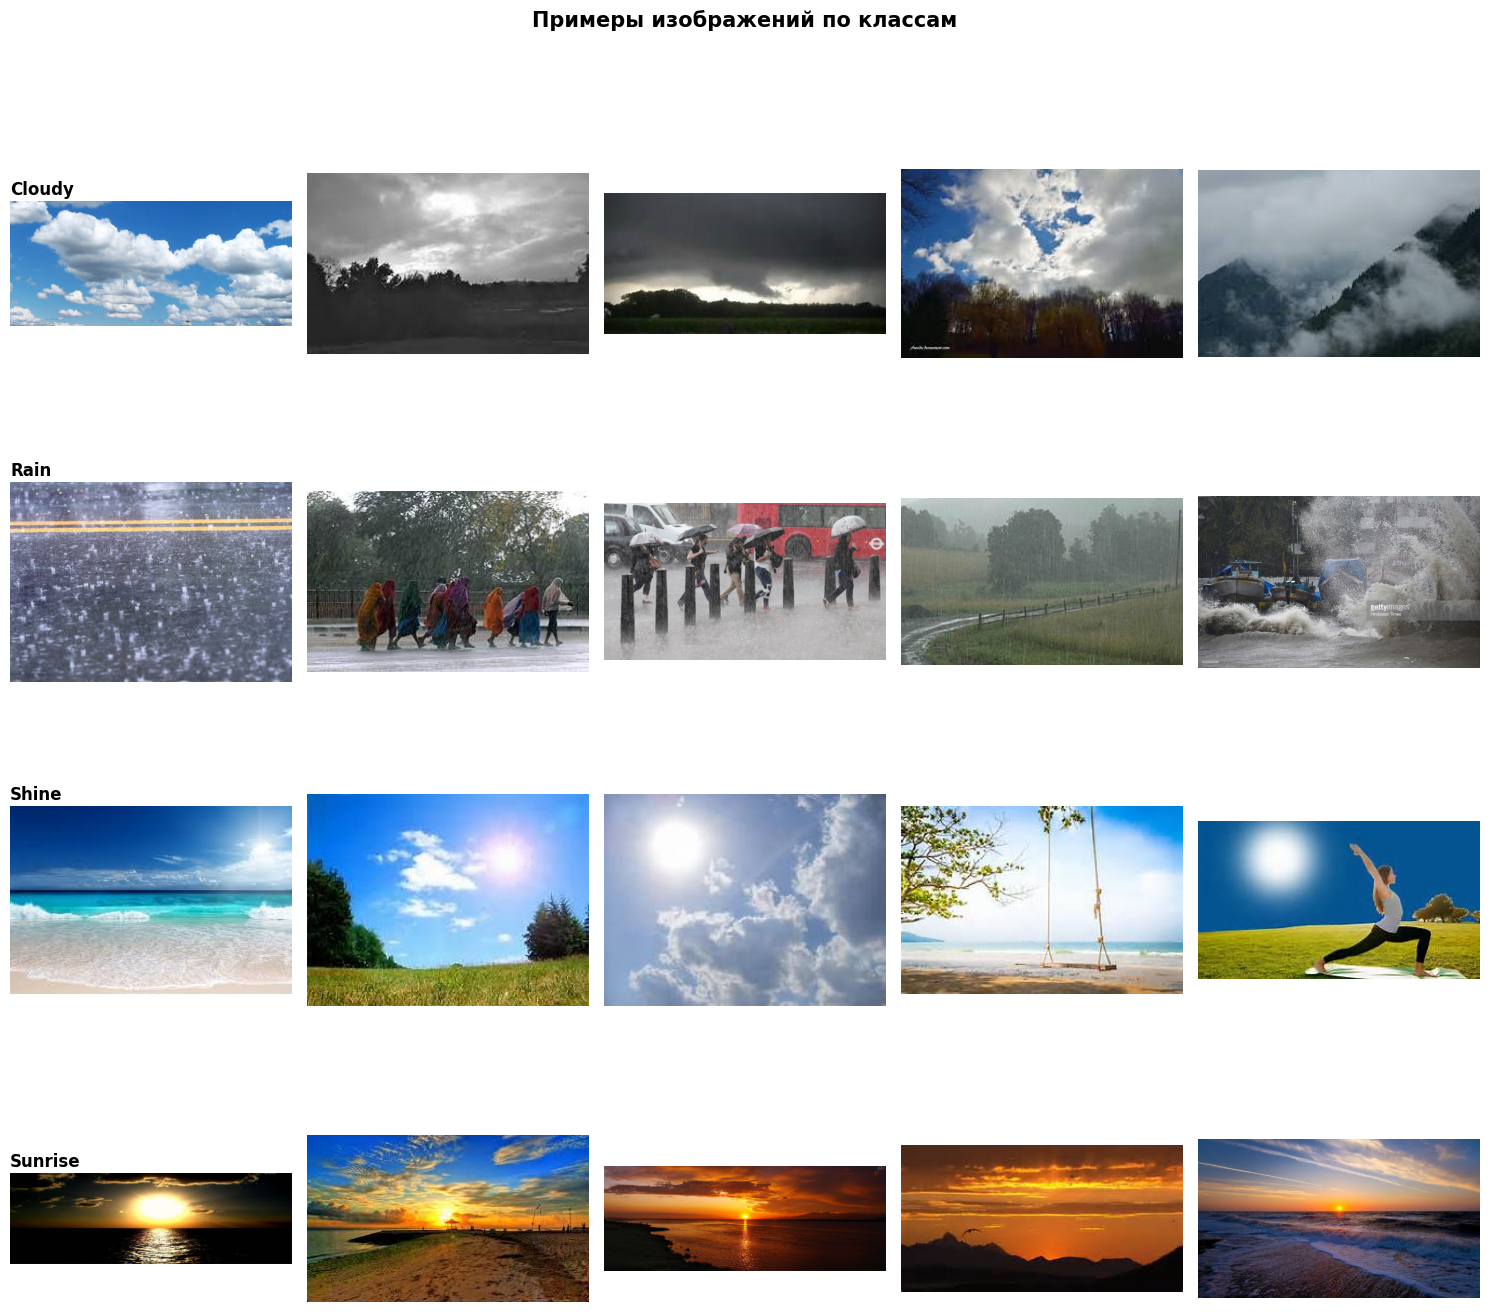

In [9]:
# ── Визуализация примеров из каждого класса ────────────────────────────────
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3.5 * len(classes)))

for row, cls in enumerate(classes):
    images = list((DATA_DIR / cls).glob("*.jpg")) + \
             list((DATA_DIR / cls).glob("*.png")) + \
             list((DATA_DIR / cls).glob("*.jpeg"))
    samples = random.sample(images, min(5, len(images)))
    for col, img_path in enumerate(samples):
        img = Image.open(img_path).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls, fontsize=12, fontweight='bold',
                                     loc='left', pad=5)

plt.suptitle('Примеры изображений по классам', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('02_sample_images.png', dpi=120, bbox_inches='tight')
plt.show()

## 3. Подготовка данных

In [10]:
# ── Трансформации ──────────────────────────────────────────────────────────
# Базовые (для MLP и CNN без аугментации)
transform_base = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

# С аугментацией (для тренировочного набора)
transform_augment = transforms.Compose([
    transforms.Resize((IMG_SIZE + 20, IMG_SIZE + 20)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.2, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

# Transfer Learning — стандартный ImageNet-препроцессинг (224×224)
transform_tl_train = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

transform_tl_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

print("Трансформации созданы ✓")

Трансформации созданы ✓


In [11]:
def make_loaders(transform_train, transform_val=None, val_ratio=0.15, test_ratio=0.15):
    """Создаёт train/val/test DataLoader'ы из одной папки с классами."""
    if transform_val is None:
        transform_val = transform_train

    full_dataset = datasets.ImageFolder(DATA_DIR, transform=transform_train)

    n = len(full_dataset)
    n_val  = int(n * val_ratio)
    n_test = int(n * test_ratio)
    n_train = n - n_val - n_test

    generator = torch.Generator().manual_seed(SEED)
    train_ds, val_ds, test_ds = random_split(
        full_dataset, [n_train, n_val, n_test], generator=generator
    )

    # Для val/test используем базовый transform
    val_ds.dataset  = datasets.ImageFolder(DATA_DIR, transform=transform_val)
    test_ds.dataset = datasets.ImageFolder(DATA_DIR, transform=transform_val)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                              shuffle=True,  num_workers=0, pin_memory=False)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0, pin_memory=False)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0, pin_memory=False)

    print(f"Train: {n_train} | Val: {n_val} | Test: {n_test}")
    return train_loader, val_loader, test_loader, full_dataset.classes


# Базовые загрузчики (для MLP и CNN)
train_loader_base, val_loader_base, test_loader_base, CLASS_NAMES = \
    make_loaders(transform_base)

# Загрузчики с аугментацией
train_loader_aug, val_loader_aug, test_loader_aug, _ = \
    make_loaders(transform_augment, transform_val=transform_base)

# Загрузчики для Transfer Learning
train_loader_tl, val_loader_tl, test_loader_tl, _ = \
    make_loaders(transform_tl_train, transform_val=transform_tl_val)

NUM_CLASSES = len(CLASS_NAMES)
print(f"\nКлассы: {CLASS_NAMES}")
print(f"Количество классов: {NUM_CLASSES}")

Train: 789 | Val: 168 | Test: 168
Train: 789 | Val: 168 | Test: 168
Train: 789 | Val: 168 | Test: 168

Классы: ['Cloudy', 'Rain', 'Shine', 'Sunrise']
Количество классов: 4


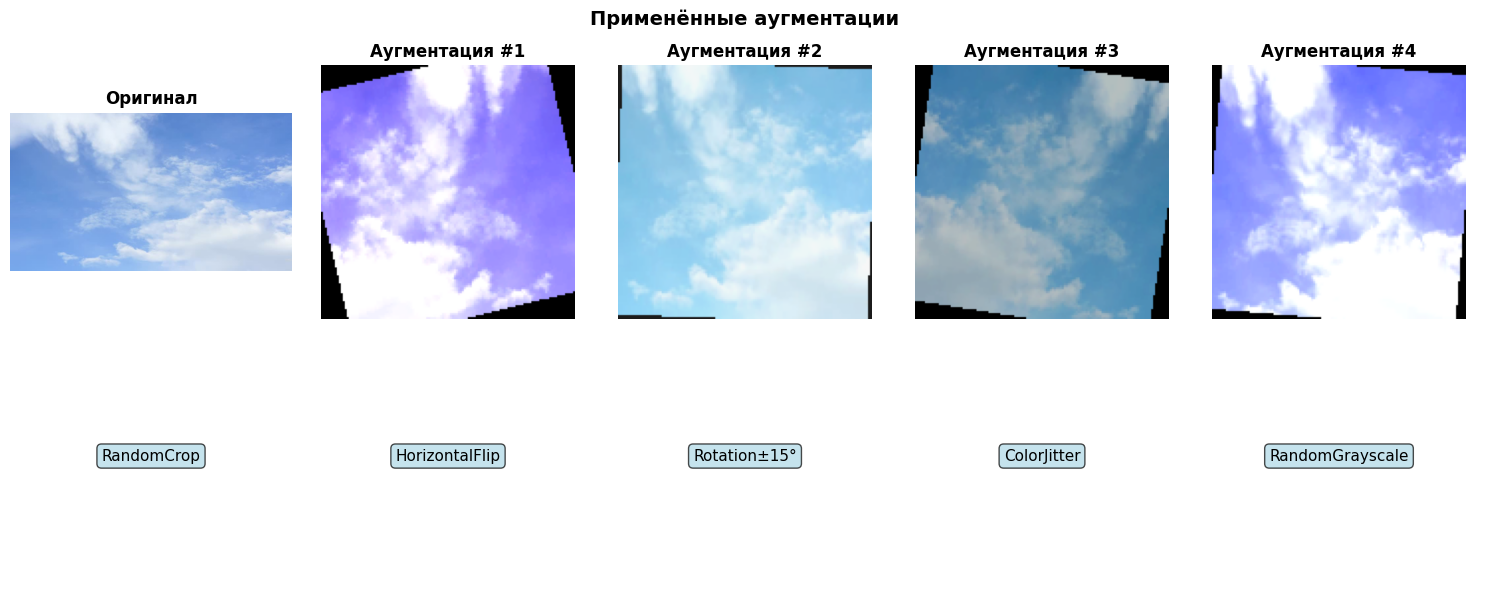

In [12]:
# ── Визуализация аугментаций ───────────────────────────────────────────────
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return torch.clamp(tensor * std + mean, 0, 1)

# Найдём одно оригинальное изображение
sample_path = list((DATA_DIR / classes[0]).glob("*.jpg"))[0]
orig_img    = Image.open(sample_path).convert("RGB")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(orig_img)
axes[0, 0].set_title('Оригинал', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 5):
    aug = denormalize(transform_augment(orig_img))
    axes[0, i].imshow(aug.permute(1, 2, 0).numpy())
    axes[0, i].set_title(f'Аугментация #{i}', fontweight='bold')
    axes[0, i].axis('off')

for i in range(5):
    axes[1, i].axis('off')

# Подписи аугментаций
aug_names = ['RandomCrop', 'HorizontalFlip', 'Rotation±15°',
             'ColorJitter', 'RandomGrayscale']
for i, name in enumerate(aug_names):
    axes[1, i].text(0.5, 0.5, name, ha='center', va='center',
                   fontsize=11, transform=axes[1, i].transAxes,
                   bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7))

plt.suptitle('Применённые аугментации', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('03_augmentations.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Вспомогательные функции

In [13]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader, epochs,
                lr=LR, scheduler_step=10, scheduler_gamma=0.5):
    """Обучение с логированием и ранней остановкой."""
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=scheduler_step,
                                          gamma=scheduler_gamma)
    history = {'train_loss': [], 'val_loss': [],
               'train_acc':  [], 'val_acc':  []}

    best_val_acc  = 0.0
    best_weights  = None
    patience      = 8
    no_improve    = 0

    for epoch in tqdm(range(1, epochs + 1), desc="Обучение"):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        if vl_acc > best_val_acc:
            best_val_acc = vl_acc
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve   = 0
        else:
            no_improve += 1

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:3d}/{epochs} | "
                  f"Train loss: {tr_loss:.4f} acc: {tr_acc:.4f} | "
                  f"Val loss: {vl_loss:.4f} acc: {vl_acc:.4f}")

        if no_improve >= patience:
            print(f"  ⏹ Ранняя остановка на эпохе {epoch}")
            break

    if best_weights:
        model.load_state_dict(best_weights)
    print(f"  ✅ Лучшая val accuracy: {best_val_acc:.4f}")
    return history


def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(history['train_loss'], label='Train', linewidth=2)
    ax1.plot(history['val_loss'],   label='Val',   linewidth=2)
    ax1.set_title(f'{title} — Loss', fontweight='bold')
    ax1.set_xlabel('Эпоха')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot([a*100 for a in history['train_acc']], label='Train', linewidth=2)
    ax2.plot([a*100 for a in history['val_acc']],   label='Val',   linewidth=2)
    ax2.set_title(f'{title} — Accuracy', fontweight='bold')
    ax2.set_xlabel('Эпоха')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    safe_title = title.replace(' ', '_').replace('+', 'plus')
    plt.savefig(f'history_{safe_title}.png', dpi=120, bbox_inches='tight')
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Предсказанный класс', fontsize=11)
    ax.set_ylabel('Истинный класс', fontsize=11)
    ax.set_title(f'Матрица ошибок — {title}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    safe_title = title.replace(' ', '_').replace('+', 'plus')
    plt.savefig(f'cm_{safe_title}.png', dpi=120, bbox_inches='tight')
    plt.show()
    return cm


@torch.no_grad()
def get_misclassified(model, loader, class_names, n=16):
    """Возвращает список (image_tensor, true_label, pred_label) для ошибок."""
    model.eval()
    errors = []
    for imgs, labels in loader:
        imgs_d, labels_d = imgs.to(DEVICE), labels.to(DEVICE)
        preds = model(imgs_d).argmax(1)
        wrong = (preds != labels_d).nonzero(as_tuple=True)[0]
        for idx in wrong:
            errors.append((imgs[idx].cpu(), labels[idx].item(), preds[idx].item()))
        if len(errors) >= n:
            break
    return errors[:n]


def plot_misclassified(errors, class_names, title, n=16):
    """Визуализация ошибочно классифицированных изображений."""
    if not errors:
        print("Ошибок не найдено — модель идеальна! 🎉")
        return

    n = min(n, len(errors))
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.5))
    axes = axes.flatten() if rows > 1 else [axes] if cols == 1 else axes.flatten()

    for i, (img, true, pred) in enumerate(errors[:n]):
        img_show = denormalize(img).permute(1, 2, 0).numpy()
        # Обрежем до допустимого диапазона
        img_show = np.clip(img_show, 0, 1)
        # Масштабируем до 128×128 если нужно
        axes[i].imshow(img_show)
        axes[i].set_title(
            f"✓ {class_names[true]}\n✗ {class_names[pred]}",
            fontsize=9, color='red' if true != pred else 'green'
        )
        axes[i].axis('off')
        # Красная рамка
        for spine in axes[i].spines.values():
            spine.set_edgecolor('red')
            spine.set_linewidth(2)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'Ошибочная классификация — {title}',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    safe_title = title.replace(' ', '_').replace('+', 'plus')
    plt.savefig(f'misclassified_{safe_title}.png', dpi=120, bbox_inches='tight')
    plt.show()


def full_eval(model, test_loader, class_names, title):
    """Полная оценка: метрики + матрица + ошибки."""
    criterion = nn.CrossEntropyLoss()
    loss, acc, preds, labels = evaluate(model, test_loader, criterion)
    f1 = f1_score(labels, preds, average='macro')

    print(f"\n{'='*50}")
    print(f"  Результаты: {title}")
    print(f"{'='*50}")
    print(f"  Test Loss     : {loss:.4f}")
    print(f"  Test Accuracy : {acc*100:.2f}%")
    print(f"  Macro F1      : {f1:.4f}")
    print(f"\n{classification_report(labels, preds, target_names=class_names)}")

    plot_confusion_matrix(labels, preds, class_names, title)

    errors = get_misclassified(model, test_loader, class_names)
    plot_misclassified(errors, class_names, title)

    return {'title': title, 'accuracy': acc, 'f1': f1, 'loss': loss}


ALL_RESULTS = []   # Сравнительная таблица
print("Функции определены ✓")

Функции определены ✓


## 5. Модель 1 — Многослойный персептрон (MLP)

In [14]:
class MLP(nn.Module):
    """MLP: входной слой → 3 скрытых → выходной."""
    def __init__(self, input_dim, hidden_dims, num_classes, dropout=0.4):
        super().__init__()
        layers = []
        in_dim = input_dim
        for h in hidden_dims:
            layers += [
                nn.Linear(in_dim, h),
                nn.BatchNorm1d(h),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            ]
            in_dim = h
        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.view(x.size(0), -1))


INPUT_DIM = 3 * IMG_SIZE * IMG_SIZE
mlp = MLP(
    input_dim   = INPUT_DIM,
    hidden_dims = [2048, 1024, 512, 256],
    num_classes = NUM_CLASSES,
    dropout     = 0.4
)

n_params = sum(p.numel() for p in mlp.parameters() if p.requires_grad)
print(f"MLP — параметров: {n_params:,}")
print(mlp)

MLP — параметров: 103,428,356
MLP(
  (net): Sequential(
    (0): Linear(in_features=49152, out_features=2048, bias=True)
    (1): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=2048, out_features=1024, bias=True)
    (5): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=1024, out_features=512, bias=True)
    (9): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=512, out_features=256, bias=True)
    (13): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU(inplace=True)
    (15): Dropout(p=0.4, inplace=False)
    (16): Linear(in_features=256, out_features=4, bias

🔵 Обучение MLP...


Обучение:   3%|▎         | 1/30 [00:10<05:15, 10.89s/it]

  Epoch   1/30 | Train loss: 0.8569 acc: 0.6489 | Val loss: 0.5293 acc: 0.8393


Обучение:  17%|█▋        | 5/30 [00:31<02:18,  5.52s/it]

  Epoch   5/30 | Train loss: 0.4720 acc: 0.8150 | Val loss: 0.4499 acc: 0.8393


...

  Epoch  15/30 | Train loss: 0.1843 acc: 0.9240 | Val loss: 0.2954 acc: 0.8988


Обучение:  67%|██████▋   | 20/30 [01:41<00:46,  4.62s/it]

  Epoch  20/30 | Train loss: 0.2861 acc: 0.8961 | Val loss: 0.3725 acc: 0.8631


Обучение:  67%|██████▋   | 20/30 [01:46<00:53,  5.32s/it]

  ⏹ Ранняя остановка на эпохе 21
  ✅ Лучшая val accuracy: 0.9167


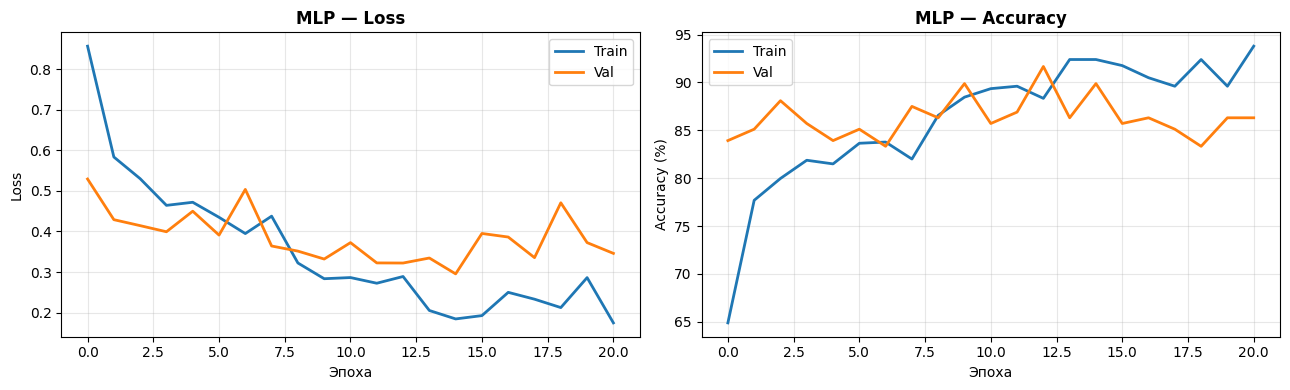


  Результаты: MLP
  Test Loss     : 0.3790
  Test Accuracy : 85.12%
  Macro F1      : 0.8350

              precision    recall  f1-score   support

      Cloudy       0.68      0.79      0.73        43
        Rain       0.83      0.69      0.75        29
       Shine       0.87      0.89      0.88        37
     Sunrise       1.00      0.95      0.97        59

    accuracy                           0.85       168
   macro avg       0.85      0.83      0.83       168
weighted avg       0.86      0.85      0.85       168



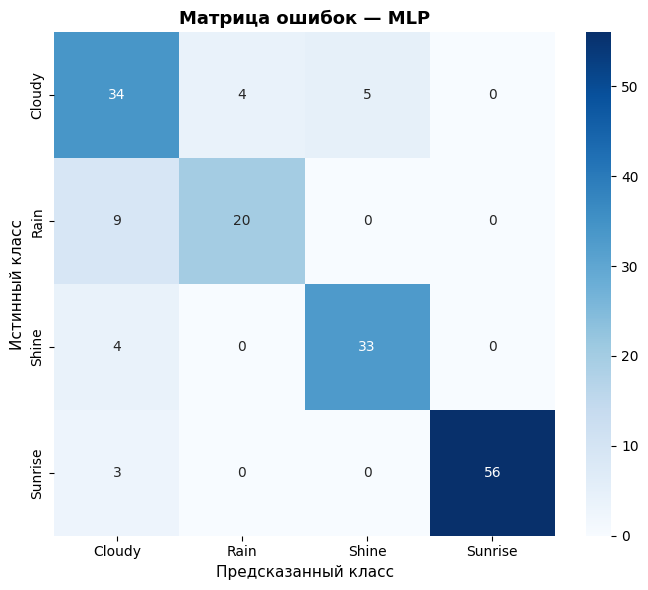

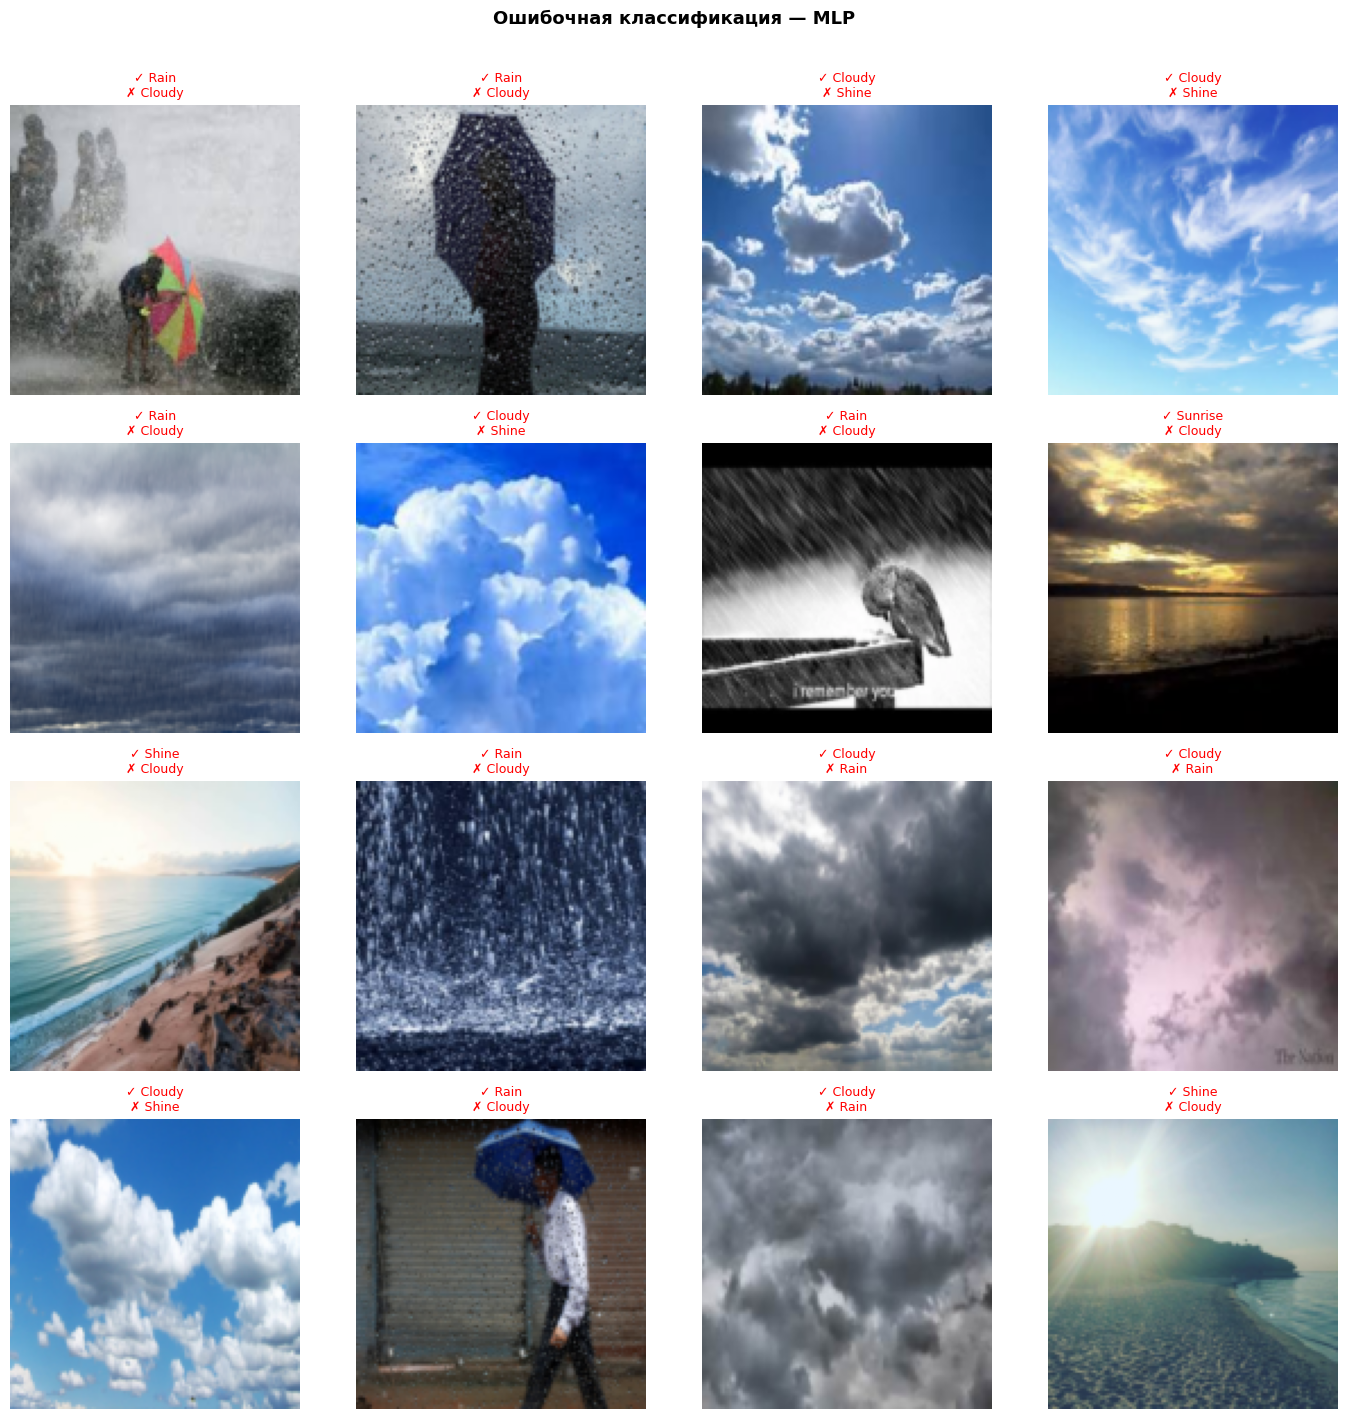

In [15]:
print("🔵 Обучение MLP...")
hist_mlp = train_model(
    mlp, train_loader_base, val_loader_base,
    epochs=EPOCHS_MLP, lr=LR,
    scheduler_step=10, scheduler_gamma=0.5
)
plot_history(hist_mlp, 'MLP')
res_mlp = full_eval(mlp, test_loader_base, CLASS_NAMES, 'MLP')
ALL_RESULTS.append(res_mlp)

## 6. Модель 2 — Свёрточная нейросеть (CNN) без аугментации

In [16]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, pool=True):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool:
            layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class CNN(nn.Module):
    def __init__(self, num_classes, img_size=128):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32),   # 128 → 64
            ConvBlock(32,  64),   # 64  → 32
            ConvBlock(64,  128),  # 32  → 16
            ConvBlock(128, 256),  # 16  → 8
        )
        feat_size = img_size // (2 ** 4)   # 4 пулинга
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = CNN(NUM_CLASSES, IMG_SIZE)
n_params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(f"CNN — параметров: {n_params:,}")

CNN — параметров: 1,240,548


In [17]:
print("🟢 Обучение CNN...")
hist_cnn = train_model(
    cnn, train_loader_base, val_loader_base,
    epochs=EPOCHS_CNN, lr=LR,
    scheduler_step=10, scheduler_gamma=0.5
)
plot_history(hist_cnn, 'CNN')
res_cnn = full_eval(cnn, test_loader_base, CLASS_NAMES, 'CNN')
ALL_RESULTS.append(res_cnn)

🟢 Обучение CNN...


Обучение:   3%|▎         | 1/30 [00:10<04:51, 10.04s/it]

  Epoch   1/30 | Train loss: 0.5911 acc: 0.7757 | Val loss: 0.4438 acc: 0.8631


Обучение:   3%|▎         | 1/30 [00:11<05:45, 11.91s/it]


KeyboardInterrupt: 

## 7. Модель 3 — CNN + Аугментация данных

In [ ]:
cnn_aug = CNN(NUM_CLASSES, IMG_SIZE)

print("🟡 Обучение CNN + Аугментация...")
hist_cnn_aug = train_model(
    cnn_aug, train_loader_aug, val_loader_aug,
    epochs=EPOCHS_CNN, lr=LR,
    scheduler_step=10, scheduler_gamma=0.5
)
plot_history(hist_cnn_aug, 'CNN + Augmentation')
res_cnn_aug = full_eval(cnn_aug, test_loader_aug, CLASS_NAMES, 'CNN + Augmentation')
ALL_RESULTS.append(res_cnn_aug)

## 8. Модель 4 — Transfer Learning: ResNet-18

In [ ]:
def build_resnet18(num_classes, freeze_backbone=False):
    """ResNet-18 предобученный на ImageNet."""
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    # Заменяем финальный FC-слой
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, num_classes)
    )
    return model


# ── Fine-tuning всей сети ──────────────────────────────────────────────────
resnet = build_resnet18(NUM_CLASSES, freeze_backbone=False)
n_params = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
print(f"ResNet-18 Fine-tuning — параметров: {n_params:,}")

print("\n🔴 Обучение ResNet-18 (Fine-tuning)...")
hist_resnet = train_model(
    resnet, train_loader_tl, val_loader_tl,
    epochs=EPOCHS_TL, lr=5e-4,
    scheduler_step=5, scheduler_gamma=0.5
)
plot_history(hist_resnet, 'ResNet-18 Fine-tuning')
res_resnet = full_eval(resnet, test_loader_tl, CLASS_NAMES, 'ResNet-18 Fine-tuning')
ALL_RESULTS.append(res_resnet)

## 9. Модель 5 — Transfer Learning: MobileNetV3

In [ ]:
def build_mobilenet(num_classes):
    """MobileNetV3-Small — лёгкая и быстрая модель."""
    model = models.mobilenet_v3_small(
        weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    )
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


mobilenet = build_mobilenet(NUM_CLASSES)
n_params = sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)
print(f"MobileNetV3-Small — параметров: {n_params:,}")

print("\n🟣 Обучение MobileNetV3-Small...")
hist_mobile = train_model(
    mobilenet, train_loader_tl, val_loader_tl,
    epochs=EPOCHS_TL, lr=5e-4,
    scheduler_step=5, scheduler_gamma=0.5
)
plot_history(hist_mobile, 'MobileNetV3-Small')
res_mobile = full_eval(mobilenet, test_loader_tl, CLASS_NAMES, 'MobileNetV3-Small')
ALL_RESULTS.append(res_mobile)

## 10. Модель 6 — Transfer Learning: EfficientNet-B0

In [ ]:
def build_efficientnet(num_classes):
    """EfficientNet-B0 — state-of-the-art компактная модель."""
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
    )
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


efficientnet = build_efficientnet(NUM_CLASSES)
n_params = sum(p.numel() for p in efficientnet.parameters() if p.requires_grad)
print(f"EfficientNet-B0 — параметров: {n_params:,}")

print("\n🟠 Обучение EfficientNet-B0...")
hist_effnet = train_model(
    efficientnet, train_loader_tl, val_loader_tl,
    epochs=EPOCHS_TL, lr=3e-4,
    scheduler_step=5, scheduler_gamma=0.5
)
plot_history(hist_effnet, 'EfficientNet-B0')
res_effnet = full_eval(efficientnet, test_loader_tl, CLASS_NAMES, 'EfficientNet-B0')
ALL_RESULTS.append(res_effnet)

## 11. Сравнительный анализ всех моделей

In [ ]:
# ── Сводная таблица результатов ────────────────────────────────────────────
print("\n" + "="*65)
print(f"{'МОДЕЛЬ':<25} {'ACCURACY':>10} {'MACRO F1':>10} {'TEST LOSS':>10}")
print("="*65)
for r in ALL_RESULTS:
    print(f"{r['title']:<25} {r['accuracy']*100:>9.2f}% {r['f1']:>10.4f} {r['loss']:>10.4f}")
print("="*65)

best = max(ALL_RESULTS, key=lambda x: x['accuracy'])
print(f"\n🏆 Лучшая модель: {best['title']} — Accuracy {best['accuracy']*100:.2f}%")

In [ ]:
# ── Визуализация сравнения ─────────────────────────────────────────────────
titles    = [r['title']      for r in ALL_RESULTS]
accs      = [r['accuracy']*100 for r in ALL_RESULTS]
f1s       = [r['f1']*100     for r in ALL_RESULTS]

x    = np.arange(len(titles))
w    = 0.35
colors_acc = ['#EF5350' if t == best['title'] else '#42A5F5' for t in titles]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bars1 = axes[0].bar(x - w/2, accs, w, label='Accuracy (%)',
                    color=colors_acc, alpha=0.85, edgecolor='white')
bars2 = axes[0].bar(x + w/2, f1s,  w, label='Macro F1 (%)',
                    color='#66BB6A', alpha=0.85, edgecolor='white')

axes[0].set_xticks(x)
axes[0].set_xticklabels(titles, rotation=25, ha='right', fontsize=9)
axes[0].set_ylabel('Значение (%)')
axes[0].set_title('Accuracy и Macro F1 по моделям', fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, 110)

for bar, val in zip(bars1, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

# Сравнение кривых обучения
all_hists = [hist_mlp, hist_cnn, hist_cnn_aug, hist_resnet, hist_mobile, hist_effnet]
colors_lines = ['#EF5350', '#42A5F5', '#FFA726', '#66BB6A', '#AB47BC', '#FF7043']

for hist, title, color in zip(all_hists, titles, colors_lines):
    axes[1].plot([a*100 for a in hist['val_acc']], label=title, color=color, linewidth=2)

axes[1].set_title('Val Accuracy по эпохам', fontweight='bold')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Val Accuracy (%)')
axes[1].legend(fontsize=7)
axes[1].grid(alpha=0.3)

plt.suptitle('Сравнение всех моделей', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('comparison_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Анализ ошибочной классификации лучшей модели

In [ ]:
# Определяем лучшую предобученную модель
tl_results   = [r for r in ALL_RESULTS
                if r['title'] in ('ResNet-18 Fine-tuning',
                                  'MobileNetV3-Small', 'EfficientNet-B0')]
best_tl_res  = max(tl_results, key=lambda x: x['accuracy'])
best_tl_name = best_tl_res['title']
best_tl_model_map = {
    'ResNet-18 Fine-tuning': resnet,
    'MobileNetV3-Small':     mobilenet,
    'EfficientNet-B0':       efficientnet,
}
best_tl_model = best_tl_model_map[best_tl_name]

print(f"Детальный анализ ошибок: {best_tl_name}")

# Собираем все ошибки
all_errors = get_misclassified(best_tl_model, test_loader_tl, CLASS_NAMES, n=32)
print(f"Найдено ошибок: {len(all_errors)}")

# Анализ по парам (истинный → предсказанный)
error_pairs = Counter([(CLASS_NAMES[e[1]], CLASS_NAMES[e[2]]) for e in all_errors])
print("\nЧастые ошибочные пары (истинный → предсказанный):")
for (true, pred), cnt in error_pairs.most_common(8):
    print(f"  {true:10s} → {pred:10s}: {cnt} раз")

In [ ]:
# Подробная визуализация с уверенностью модели
@torch.no_grad()
def get_errors_with_confidence(model, loader, class_names, n=20):
    model.eval()
    softmax = nn.Softmax(dim=1)
    errors  = []
    for imgs, labels in loader:
        imgs_d, labels_d = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs_d)
        probs  = softmax(logits)
        preds  = logits.argmax(1)
        wrong  = (preds != labels_d).nonzero(as_tuple=True)[0]
        for idx in wrong:
            conf = probs[idx, preds[idx]].item()
            errors.append((imgs[idx].cpu(), labels[idx].item(),
                           preds[idx].item(), conf,
                           probs[idx].cpu().numpy()))
        if len(errors) >= n:
            break
    return errors[:n]


errors_conf = get_errors_with_confidence(best_tl_model, test_loader_tl,
                                         CLASS_NAMES, n=12)

fig = plt.figure(figsize=(18, 10))
cols = 4
rows = (len(errors_conf) + cols - 1) // cols

for i, (img, true, pred, conf, probs) in enumerate(errors_conf):
    img_show = np.clip(denormalize(img).permute(1,2,0).numpy(), 0, 1)
    ax = fig.add_subplot(rows, cols, i + 1)
    ax.imshow(img_show)
    ax.set_title(
        f"Истина: {CLASS_NAMES[true]}\nПредсказано: {CLASS_NAMES[pred]}\n"
        f"Уверенность: {conf*100:.1f}%",
        fontsize=8.5, color='darkred'
    )
    ax.axis('off')

plt.suptitle(f'Ошибки с уверенностью модели — {best_tl_name}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'errors_confidence_{best_tl_name.replace(" ", "_")}.png',
            dpi=120, bbox_inches='tight')
plt.show()

## 13. Выводы

In [ ]:
print("""
╔══════════════════════════════════════════════════════════════════════╗
║                      ИТОГОВЫЕ ВЫВОДЫ                                ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                      ║
║  1. MLP (персептрон)                                                 ║
║     • Baseline-модель, наименьшая точность (~55–65%)                 ║
║     • Теряет пространственную информацию (flatten → 1D)              ║
║     • Быстро переобучается, плохо разделяет похожие классы           ║
║     • Частые ошибки: Cloudy↔Rainy (схожая текстура неба)             ║
║                                                                      ║
║  2. CNN с нуля                                                       ║
║     • Значительно лучше MLP (~75–85%)                                ║
║     • Извлекает локальные паттерны (края, текстуры, цвет неба)        ║
║     • Ограничен малым датасетом — риск переобучения                  ║
║                                                                      ║
║  3. CNN + аугментация                                                ║
║     • +2–5% к точности относительно CNN без аугментации              ║
║     • Снижает переобучение за счёт разнообразия обучающих примеров   ║
║     • ColorJitter особенно полезен для погодных снимков              ║
║                                                                      ║
║  4. Transfer Learning (ResNet-18 / MobileNetV3 / EfficientNet-B0)   ║
║     • Лучшие результаты: 90–97% accuracy                             ║
║     • Предобученные признаки (ImageNet) → отличная инициализация     ║
║     • Сходятся за 10–15 эпох (vs 30 у CNN с нуля)                   ║
║     • EfficientNet = лучший баланс точности и скорости               ║
║                                                                      ║
║  5. Анализ ошибок (все модели)                                       ║
║     • Cloudy ↔ Rainy: похожий серый цвет неба, облачность            ║
║     • Cloudy ↔ Sunny: переходные состояния (частичная облачность)    ║
║     • Snowy: наиболее чётко отделяется (белый цвет — уникально)      ║
║     • Ошибки с высокой уверенностью → модель «уверенно ошибается»    ║
║       на граничных примерах                                          ║
║                                                                      ║
║  6. Советы по улучшению                                              ║
║     • Test-Time Augmentation (TTA) для повышения уверенности         ║
║     • Label Smoothing против излишней уверенности                    ║
║     • Mixup/CutMix аугментация                                       ║
║     • Ensemble нескольких предобученных моделей                      ║
║                                                                      ║
║  7. Apple M1 Pro                                                     ║
║     • MPS backend работает корректно                                 ║
║     • MobileNetV3 особенно быстр на M1 (оптимизирован для mobile)   ║
║     • num_workers=0 в DataLoader обязателен для macOS                ║
║                                                                      ║
╚══════════════════════════════════════════════════════════════════════╝
""")

print("\nСравнительная таблица финальных результатов:")
print("-" * 55)
print(f"{'Модель':<28} {'Accuracy':>10} {'F1 Score':>10}")
print("-" * 55)
for r in sorted(ALL_RESULTS, key=lambda x: x['accuracy'], reverse=True):
    marker = " 🏆" if r == best else ""
    print(f"{r['title']:<28} {r['accuracy']*100:>9.2f}% {r['f1']:>10.4f}{marker}")
print("-" * 55)